In [105]:
import pandas as pd

# clear duplicate data

df=pd.read_csv('rssi.csv')
df_cleaned=df.dropna()
df_cleaned=df_cleaned.drop_duplicates()

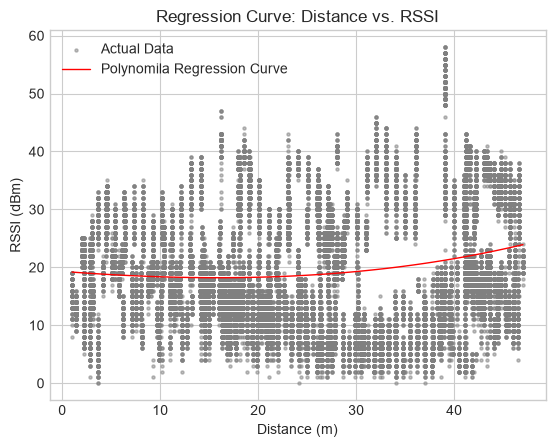

R-squared value of  Polynomial Regression: 0.0289


In [106]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

first_ap=df_cleaned['ap'].unique()[0]
df_single_ap=df_cleaned[df_cleaned['ap']==first_ap].copy()
df_single_ap['Distance']=np.sqrt(df_single_ap['x']**2+df_single_ap['y']**2+df_single_ap['z']**2)

# Polynomial Regression

X=df_single_ap[['Distance']].to_numpy()
Y=df_single_ap['signal'].to_numpy()

poly=PolynomialFeatures(degree=3)
X_poly=poly.fit_transform(X)

model=LinearRegression()
model.fit(X_poly,Y)

X_plot=np.linspace(X.min(),X.max(),100).reshape(-1,1)
Y_plot=model.predict(poly.transform(X_plot))

# Plotting predicted data

plt.scatter(X, Y, color='gray', s=5, alpha=0.5, label='Actual Data')
plt.plot(X_plot, Y_plot, color='red', linewidth=1, label='Polynomila Regression Curve')
plt.xlabel('Distance (m)')
plt.ylabel('RSSI (dBm)')
plt.title('Regression Curve: Distance vs. RSSI')
plt.legend()
plt.show()

# R-squared value

Y_pred_poly=model.predict(X_poly)
r2=r2_score(Y,Y_pred_poly)
print(f'R-squared value of  Polynomial Regression: {r2:.4f}')


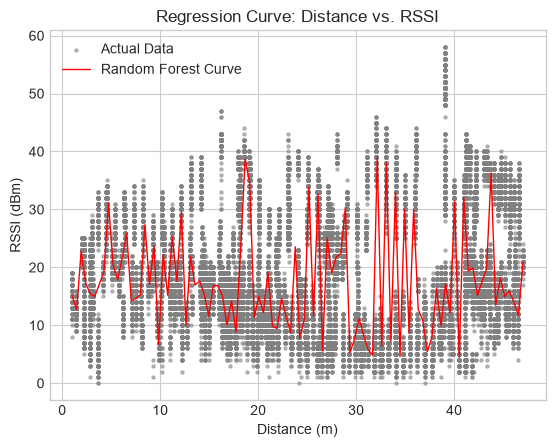

R-squared value of Random Forest Model: 0.8438


In [107]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Random Forest 
# Have used 100 Decision Trees 

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X, Y) 

X_plot_rf = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
Y_plot_rf = rf_model.predict(X_plot_rf)

# Plotting predicted data

plt.scatter(X, Y, color='gray', s=5, alpha=0.5, label='Actual Data')
plt.plot(X_plot_rf, Y_plot_rf, color='red', linewidth=1, label='Random Forest Curve')
plt.xlabel('Distance (m)')
plt.ylabel('RSSI (dBm)')
plt.title('Regression Curve: Distance vs. RSSI')
plt.legend()
plt.show()

# R-squared value

Y_pred_rf = rf_model.predict(X)
r2_rf = r2_score(Y, Y_pred_rf)
print(f'R-squared value of Random Forest Model: {r2_rf:.4f}')


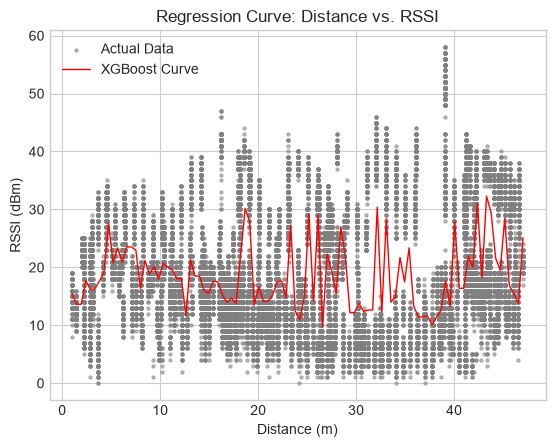

R-squared value of XGBoost Model: 0.6754


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import r2_score

# XGBoost Regressor 

xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
xgb_model.fit(X, Y)

X_plot_xgb = np.linspace(X.min(),X.max(),100).reshape(-1,1)
Y_plot_xgb = xgb_model.predict(X_plot_xgb)

# Plotting predicted data

plt.scatter(X, Y, color='gray', s=5, alpha=0.5, label='Actual Data')
plt.plot(X_plot_xgb, Y_plot_xgb, color='red', linewidth=1, label='XGBoost Curve')
plt.xlabel('Distance (m)')
plt.ylabel('RSSI (dBm)')
plt.title('Regression Curve: Distance vs. RSSI')
plt.legend()
plt.show()

# R-squared value

Y_pred_xgb = xgb_model.predict(X)
r2_xgb = r2_score(Y, Y_pred_xgb)
print(f"R-squared value of XGBoost Model: {r2_xgb:.4f}")


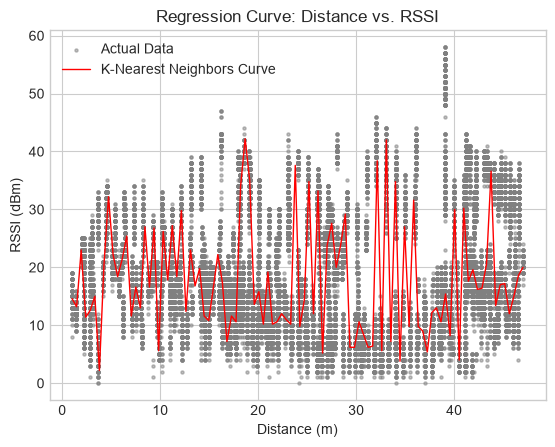

R-squared value of K-Nearest Neighbors Model: 0.6909


In [109]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score

# K-Nearest Neighbors Regressor

knn_model = KNeighborsRegressor(n_neighbors=5, weights = 'distance')
knn_model.fit(X, Y)

X_plot_knn = np.linspace(X.min(),X.max(),100).reshape(-1,1)
Y_plot_knn = knn_model.predict(X_plot_knn)

# Plotting predicted data

plt.scatter(X, Y, color='gray', s=5, alpha=0.5, label='Actual Data')
plt.plot(X_plot_knn, Y_plot_knn, color='red', linewidth=1, label='K-Nearest Neighbors Curve')
plt.xlabel('Distance (m)')
plt.ylabel('RSSI (dBm)')
plt.title('Regression Curve: Distance vs. RSSI')
plt.legend()
plt.show()

# R-Squared value

Y_pred_knn = knn_model.predict(X)
r2_knn = r2_score(Y, Y_pred_knn)
print(f'R-squared value of K-Nearest Neighbors Model: {r2_knn:.4f}')




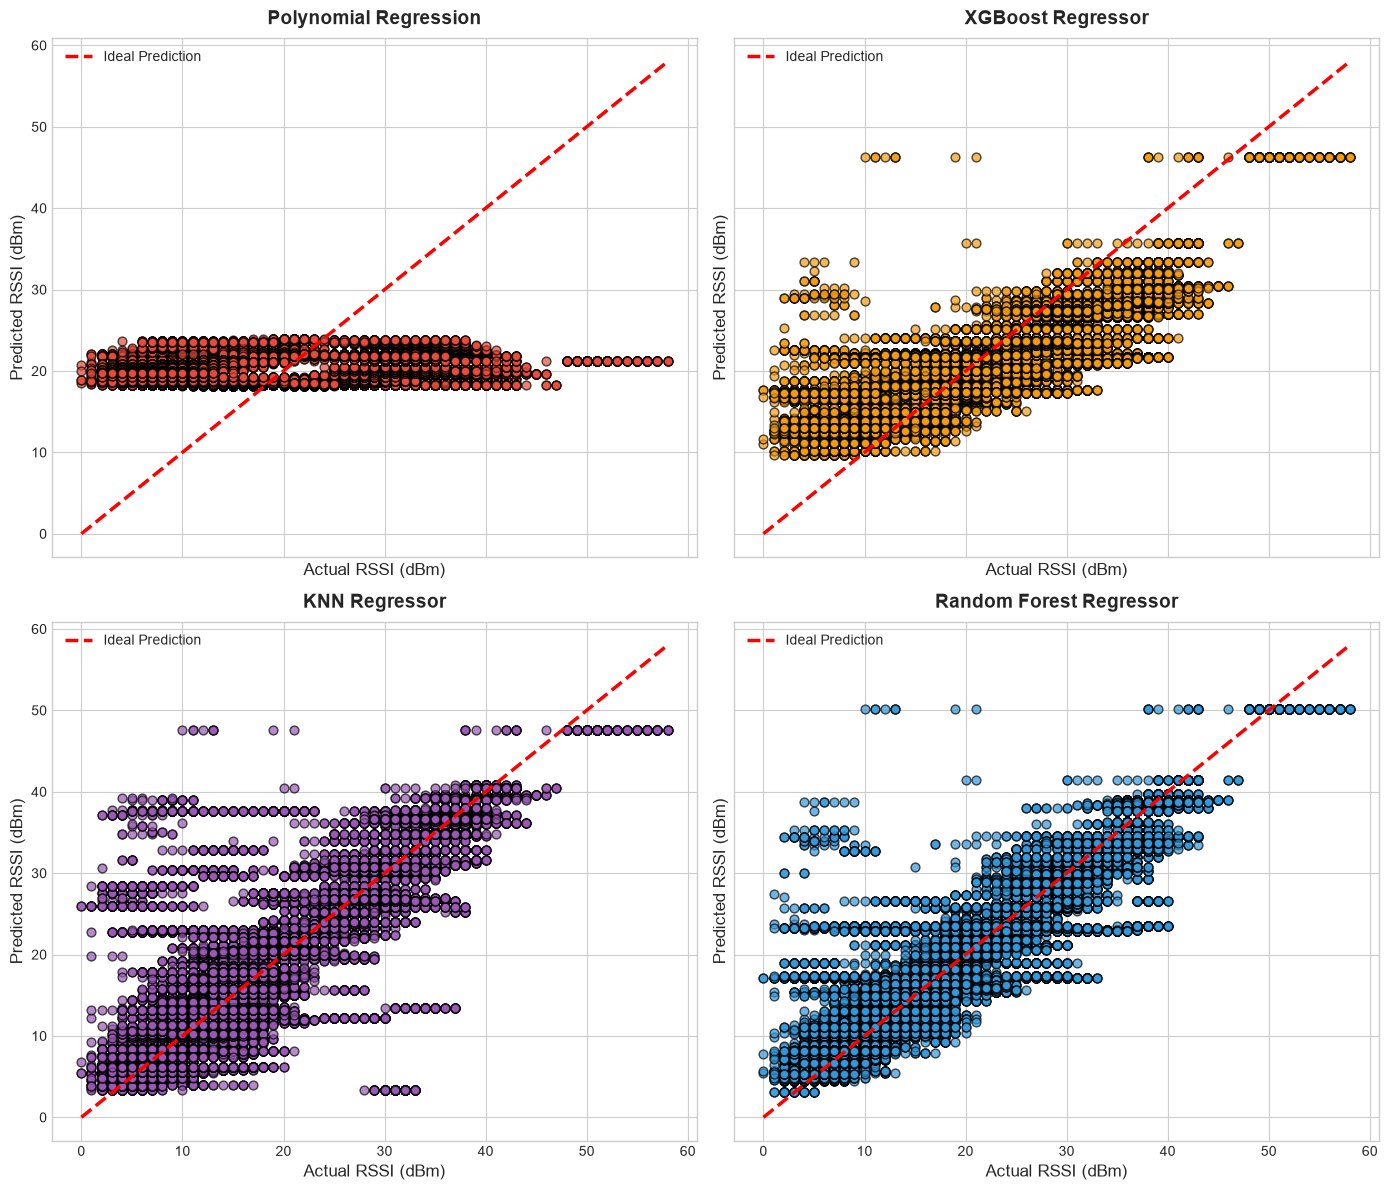

In [110]:
# Plotting actual Vs predicted data for three models

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharey=True, sharex=True)
plt.style.use('seaborn-v0_8-whitegrid')

axes = axes.flatten()

predictions = [Y_pred_poly, Y_pred_xgb, Y_pred_knn, Y_pred_rf] 
titles = ['Polynomial Regression', 'XGBoost Regressor', 'KNN Regressor', 'Random Forest Regressor']
colors = ['#e74c3c', '#f39c12', '#9b59b6', '#3498db']

for i in range(4):
    ax = axes[i]
    
    ax.scatter(Y, predictions[i], alpha=0.7, color=colors[i], edgecolor='black', s=40)
    
    min_val = min(np.min(Y), np.min(predictions[i]))
    max_val = max(np.max(Y), np.max(predictions[i]))
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2.5, label='Ideal Prediction')
    
    ax.set_title(titles[i], fontsize=14, fontweight='bold', pad=10)
    ax.set_xlabel('Actual RSSI (dBm)', fontsize=12)
    ax.set_ylabel('Predicted RSSI (dBm)', fontsize=12)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

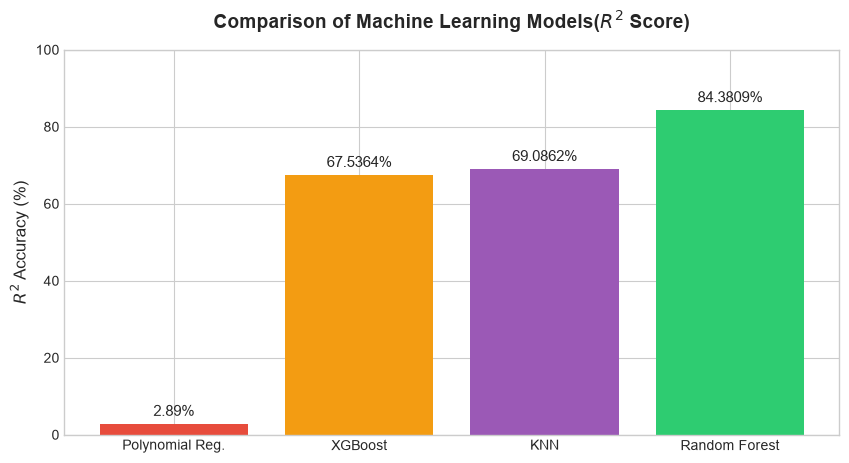

In [111]:
# Plotting accuracies of three models

import matplotlib.pyplot as plt
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(10,5),dpi=100)
models=['Polynomial Reg.','XGBoost','KNN','Random Forest']
r2_values=[round(r2*100,4),round(r2_xgb*100,4),round(r2_knn*100,4),round(r2_rf*100,4)]

bars=plt.bar(models,r2_values,color=['#e74c3c','#f39c12','#9b59b6','#2ecc71'])

plt.title('Comparison of Machine Learning Models($R^2$ Score)',fontsize=14,fontweight='bold',pad=15)
plt.ylabel('$R^2$ Accuracy (%)',fontsize=12)
plt.ylim(0,100)

for bar in bars:
    yval=bar.get_height()
    plt.text(bar.get_x()+bar.get_width()/2,yval+2,f'{yval}%',ha='center',fontsize=11)

plt.show()


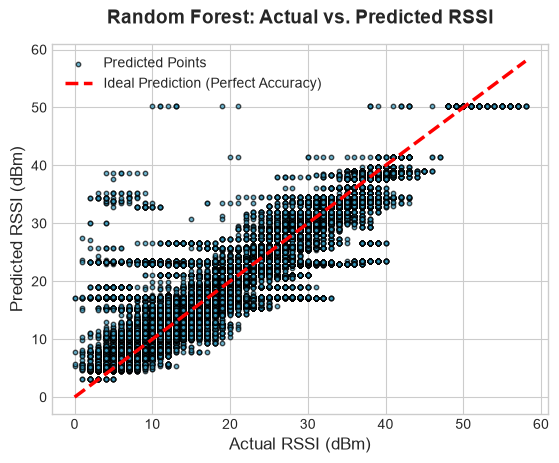

In [112]:
# Accuracy of predictions using Random Forest

import matplotlib.pyplot as plt
import numpy as np

plt.scatter(Y,y_pred_rf,alpha=0.7,color='#3498bd',edgecolor='black',s=10,label='Predicted Points')

min_val = min(np.min(Y), np.min(y_pred_rf))
max_val = max(np.max(Y), np.max(y_pred_rf))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2.5, label='Ideal Prediction (Perfect Accuracy)')

plt.title('Random Forest: Actual vs. Predicted RSSI', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Actual RSSI (dBm)', fontsize=12)
plt.ylabel('Predicted RSSI (dBm)', fontsize=12)
plt.legend(loc='upper left', fontsize=10)

plt.show()